# Assignment 9: Data Visualization

| | |
|---|---|
| **Student** | Lokesh Patwal |
| **Programme** | Yuva Intern - Data Science Fundamentals Assessment |
| **Assignment** | 9 of 10 |

## 2. Aim
To create the seven most common chart types with Matplotlib and Seaborn, choose the right chart for each question, and explain what each chart shows.

## 3. Objectives
1. Draw bar, line, histogram, pie, scatter, box and heat-map charts.
2. Add titles, axis labels, units and legends.
3. Save every chart as a PNG in `visualizations/`.
4. Explain the insight each chart gives.
5. Know when a chart type is the wrong choice.

## 4. Introduction and Theory
**Matplotlib** draws charts from the ground up (`fig, ax = plt.subplots()`); **Seaborn** builds statistical charts on top of it with less code.

| Question | Best chart |
|---|---|
| Compare amounts across categories | **Bar** |
| Change over time | **Line** |
| Distribution of one number | **Histogram** (or box plot) |
| Share of a whole (few parts) | **Pie** |
| Relationship of two numbers | **Scatter** |
| Compare spread across groups, spot outliers | **Box plot** |
| Many pairwise values at once | **Heat map** |

Good charts have a title that says the message, labelled axes with units, readable fonts, honest axes (bar charts start at zero) and no unnecessary decoration.

## 5. Software and Libraries Required
Python 3, Matplotlib, Seaborn, pandas, NumPy, scikit-learn (to load datasets).

## 6. Dataset Details
* **Iris** (Fisher, 1936; UCI, https://archive.ics.uci.edu/dataset/53/iris): histogram, scatter, box plot.
* **Wine** (Forina et al., 1991; UCI, https://archive.ics.uci.edu/dataset/109/wine): bar chart, pie chart, heat map.
* **Stocks.csv** (monthly prices from Yahoo Finance, https://finance.yahoo.com; shipped with Matplotlib sample data): line chart.

Seaborn's own sample datasets need an internet download, so they are not used; the three files above work offline and on Colab.

## 7. Step-by-Step Procedure
1. Load the data and set a common style. 2. Draw the seven charts, each followed by its explanation. 3. Check that all files were saved.

## 8. Complete Python Code and 9. Expected Output
The charts under each code cell are the actual figures produced when this notebook was executed.

### Step 1: Setup and data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris, load_wine

sns.set_theme(style="whitegrid", font_scale=1.0)
OUT = Path("../visualizations")
OUT.mkdir(exist_ok=True)
BLUE, ORANGE, GREEN = "#2F6DB5", "#E8833A", "#3A9D5D"

iris = load_iris(as_frame=True).data
iris.columns = [c.replace(" (cm)", "").replace(" ", "_") for c in iris.columns]
iris["species"] = load_iris().target_names[load_iris().target]

wine = load_wine(as_frame=True).frame
wine["cultivar"] = wine.pop("target").map({0: "Class 0", 1: "Class 1", 2: "Class 2"})

stocks = pd.read_csv(Path(matplotlib.get_data_path()) / "sample_data" / "Stocks.csv", comment="#", parse_dates=["Date"])
stocks = stocks.dropna(subset=["IBM", "AAPL", "MSFT"]).set_index("Date")
print("iris", iris.shape, "| wine", wine.shape, "| stocks (rows with prices)", stocks.shape)

iris (150, 5) | wine (178, 14) | stocks (rows with prices) (391, 10)


### Chart 1: Bar chart - compare categories

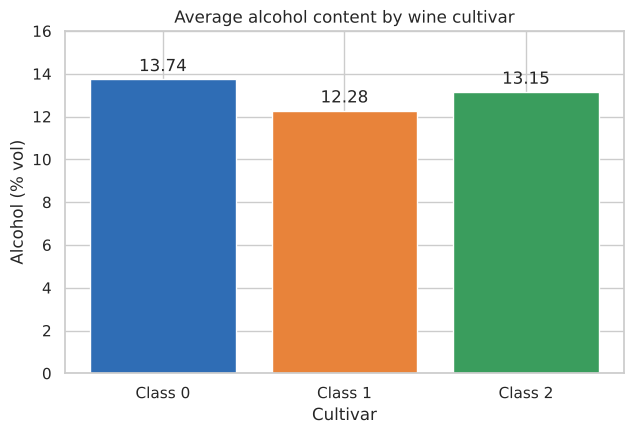

In [2]:
mean_alcohol = wine.groupby("cultivar")["alcohol"].mean()
fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(mean_alcohol.index, mean_alcohol.values, color=[BLUE, ORANGE, GREEN])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set(title="Average alcohol content by wine cultivar", xlabel="Cultivar", ylabel="Alcohol (% vol)", ylim=(0, 16))
fig.tight_layout()
fig.savefig(OUT / "a9_01_bar_alcohol_by_cultivar.png", dpi=150)
plt.show()

**What it shows:** one bar per cultivar, with the height equal to the average alcohol content. **Insight:** Class 0 has the highest alcohol average (`13.74 %`) and Class 1 the lowest (`12.28 %`). The bar axis starts at zero so the bar heights are honest.

### Chart 2: Line chart - change over time

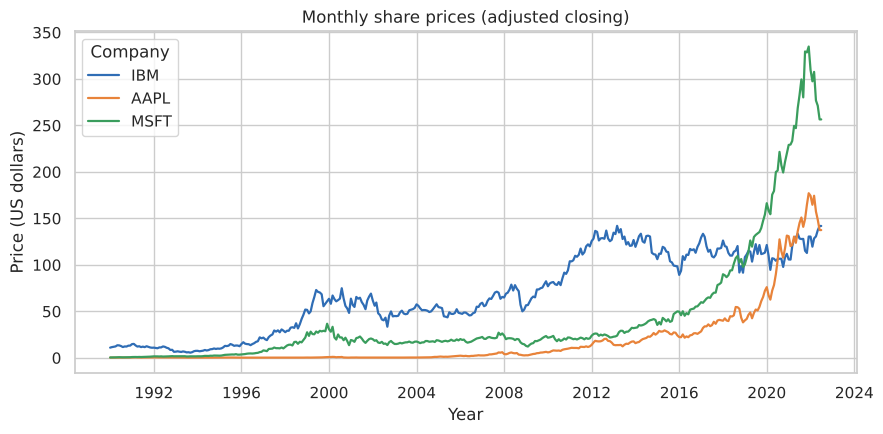

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for ticker, colour in [("IBM", BLUE), ("AAPL", ORANGE), ("MSFT", GREEN)]:
    ax.plot(stocks.index, stocks[ticker], label=ticker, color=colour, linewidth=1.6)
ax.set(title="Monthly share prices (adjusted closing)", xlabel="Year", ylabel="Price (US dollars)")
ax.legend(title="Company")
fig.tight_layout()
fig.savefig(OUT / "a9_02_line_stock_prices.png", dpi=150)
plt.show()

**What it shows:** price against time for three companies. **Insight:** on the last date Microsoft is at 256, IBM at 142 and Apple at 137 dollars, although all three started below 15 dollars in 1990. The lines cross several times, so the ranking of the companies changed over the years. Lines are ideal when order in time matters.

### Chart 3: Histogram - one distribution

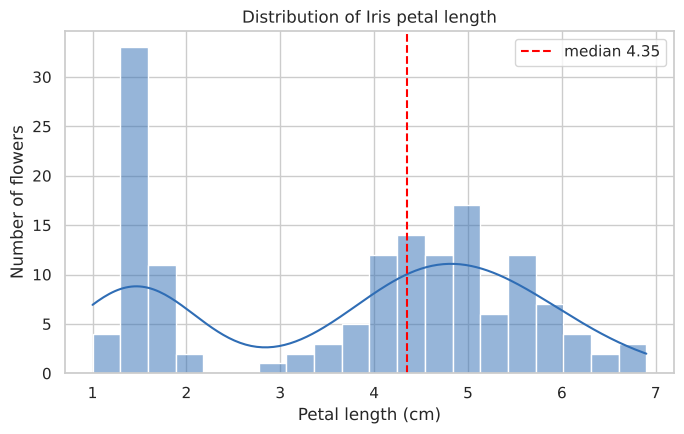

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.histplot(iris["petal_length"], bins=20, kde=True, color=BLUE, ax=ax)
ax.axvline(iris["petal_length"].median(), color="red", linestyle="--", label=f"median {iris['petal_length'].median():.2f}")
ax.set(title="Distribution of Iris petal length", xlabel="Petal length (cm)", ylabel="Number of flowers")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "a9_03_histogram_petal_length.png", dpi=150)
plt.show()

**What it shows:** how many flowers fall in each petal-length range. **Insight:** the shape has two humps (bimodal), a short-petal group around 1.5 cm and a long-petal group around 4-6 cm. A single average (3.76 cm) would fall in the empty gap between them.

### Chart 4: Pie chart - share of a whole

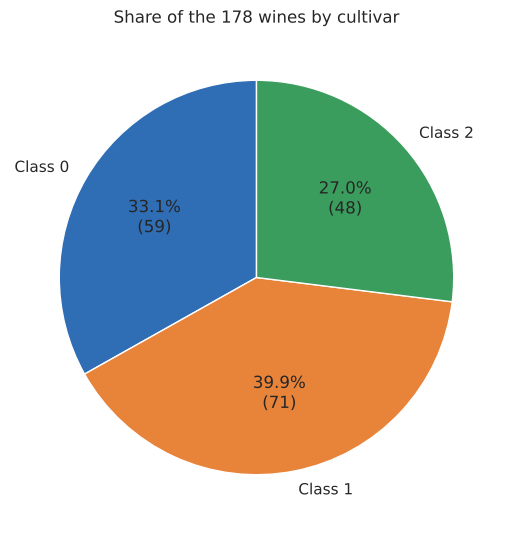

In [5]:
counts = wine["cultivar"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(counts, labels=counts.index, autopct=lambda p: f"{p:.1f}%\n({round(p * counts.sum() / 100)})",
       colors=[BLUE, ORANGE, GREEN], startangle=90, wedgeprops={"edgecolor": "white"})
ax.set_title("Share of the 178 wines by cultivar")
fig.tight_layout()
fig.savefig(OUT / "a9_04_pie_cultivar_share.png", dpi=150)
plt.show()

**What it shows:** each cultivar's share of all wines. **Insight:** Class 1 is the biggest group (`71` wines) and Class 2 the smallest (`48`). Pie charts work only for a few parts that add up to a whole; with many categories or similar sizes a bar chart is easier to read.

### Chart 5: Scatter plot - relationship between two numbers

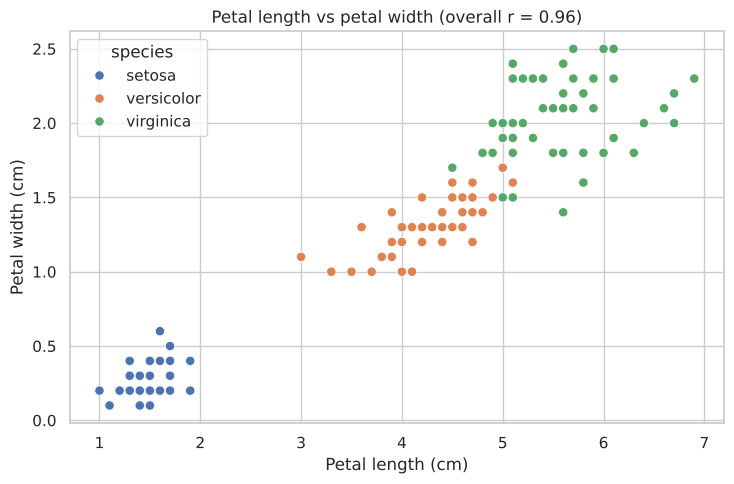

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.scatterplot(data=iris, x="petal_length", y="petal_width", hue="species", s=45, ax=ax)
r = iris["petal_length"].corr(iris["petal_width"])
ax.set(title=f"Petal length vs petal width (overall r = {r:.2f})", xlabel="Petal length (cm)", ylabel="Petal width (cm)")
fig.tight_layout()
fig.savefig(OUT / "a9_05_scatter_petal.png", dpi=150)
plt.show()

**What it shows:** one dot per flower. **Insight:** longer petals are also wider (`r = 0.96`), and colour shows that the species form three separate clouds. A strong correlation is not proof that one measurement causes the other.

### Chart 6: Box plot - compare spread across groups

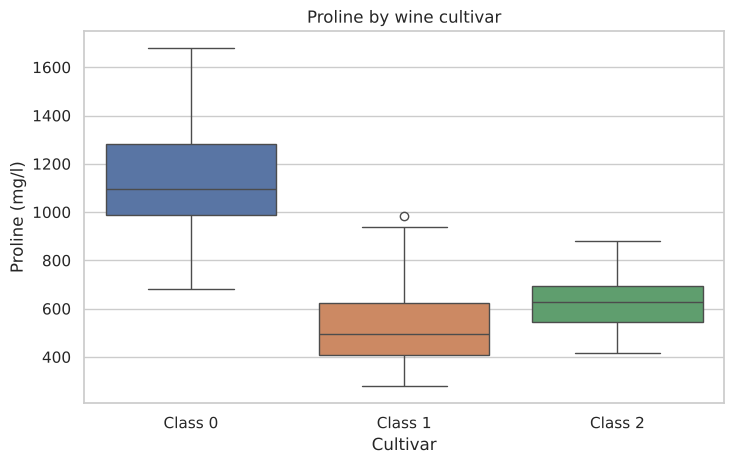

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.boxplot(data=wine, x="cultivar", y="proline", hue="cultivar", legend=False, ax=ax)
ax.set(title="Proline by wine cultivar", xlabel="Cultivar", ylabel="Proline (mg/l)")
fig.tight_layout()
fig.savefig(OUT / "a9_06_boxplot_proline.png", dpi=150)
plt.show()
medians = wine.groupby("cultivar")["proline"].median()

**What it shows:** the box covers the middle 50% of values (Q1 to Q3), the line inside is the median, the whiskers show the usual range and dots mark possible outliers. **Insight:** the median proline of Class 0 is `1095.0`, about `2.2` times that of Class 1 (`495.0`), so proline is a strong feature for telling the cultivars apart.

### Chart 7: Heat map - many relationships at once

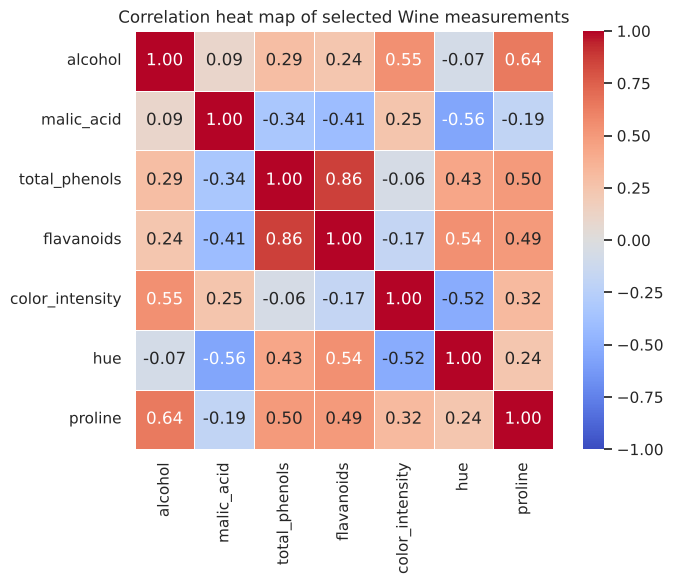

In [8]:
features = ["alcohol", "malic_acid", "total_phenols", "flavanoids", "color_intensity", "hue", "proline"]
corr = wine[features].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation heat map of selected Wine measurements")
fig.tight_layout()
fig.savefig(OUT / "a9_07_heatmap_wine_correlation.png", dpi=150)
plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna().sort_values()

**What it shows:** the correlation of every pair of measurements as a colour (red = positive, blue = negative). **Insight:** the strongest positive pair is `total_phenols` and `flavanoids` (`0.86`), and the strongest negative pair is `malic_acid` and `hue` (`-0.56`).

### Step 10: Validation - were all seven charts saved?

In [9]:
files = sorted(OUT.glob("a9_*.png"))
for f in files:
    print(f"{f.name:<42} {f.stat().st_size / 1024:6.1f} KB")
assert len(files) == 7 and all(f.stat().st_size > 10_000 for f in files)
assert abs(counts.sum() - 178) == 0 and mean_alcohol.idxmax() == "Class 0"
print("All validation checks passed: 7 charts saved.")

a9_01_bar_alcohol_by_cultivar.png            34.2 KB
a9_02_line_stock_prices.png                 106.0 KB
a9_03_histogram_petal_length.png             48.4 KB
a9_04_pie_cultivar_share.png                 48.6 KB
a9_05_scatter_petal.png                      76.0 KB
a9_06_boxplot_proline.png                    32.9 KB
a9_07_heatmap_wine_correlation.png          131.1 KB
All validation checks passed: 7 charts saved.


## 10. Output Explanation
The seven figures above are real outputs of this run. The numbers quoted under each chart are computed from the data, not typed in. Together they show: a **bar** chart comparing averages (`{'Class 0': 13.74, 'Class 1': 12.28, 'Class 2': 13.15}`), a **line** chart of three share prices over `1990-2022`, a **histogram** with two humps, a **pie** chart of `[59, 71, 48]` wines per cultivar, a **scatter plot** with `r = 0.96`, a **box plot** of proline medians `{'Class 0': 1095.0, 'Class 1': 495.0, 'Class 2': 627.5}`, and a **heat map** of 7 chemical features.

## 11. Observations and Analysis
* The same chart type can mislead if the axis is cut (bars must start at zero) or if too many categories are used (pie).
* Colour should carry meaning: the same three colours always stand for the same three groups or companies.
* A histogram or box plot reveals structure (two humps, outliers) that a single average hides.
* Heat maps compress many numbers into one picture but show only *linear* association between pairs.
* Every chart has a title, axis labels with units and a legend where more than one series appears.

**Common mistakes**
| Mistake | Fix |
|---|---|
| Missing title/labels/units | Always set `title`, `xlabel`, `ylabel` |
| Pie chart with many slices | Use a bar chart |
| Forgetting `plt.tight_layout()` | Labels get cut off |
| Saving after `plt.show()` | Call `savefig` first (as done here) |

**Practice tasks**
1. Draw a horizontal bar chart of the mean flavanoids per cultivar.
2. Plot AAPL and MSFT on the same line chart using a log-scale y-axis.
3. Create a violin plot of sepal length by species with `sns.violinplot`.

## 12. Result / Conclusion
Seven chart types were created, saved to `visualizations/` and interpreted. The assignment shows that the question you ask decides the chart you choose, and that clear labelling and honest scales matter as much as the code.